In [65]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [27]:
dataset = pd.read_csv('./Salary.csv')
dataset.head(3)

,Age,YearsExperience,EducationLevel,Salary
0,28,1,Master,56512
1,35,8,Master,91587
2,55,5,Bachelor,70520


In [28]:
# checking the shape (number of rows and columns) of the dataset
dataset.shape

(2000, 4)

In [29]:
# checking for missing/null values in the dataset
dataset.isnull().sum()

Age                0
YearsExperience    0
EducationLevel     0
Salary             0
dtype: int64

In [30]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Age              2000 non-null   int64
 1   YearsExperience  2000 non-null   int64
 2   EducationLevel   2000 non-null   str  
 3   Salary           2000 non-null   int64
dtypes: int64(3), str(1)
memory usage: 62.6 KB


In [31]:
dataset['EducationLevel'].value_counts()

EducationLevel
Bachelor      910
Master        481
HighSchool    401
PhD           208
Name: count, dtype: int64

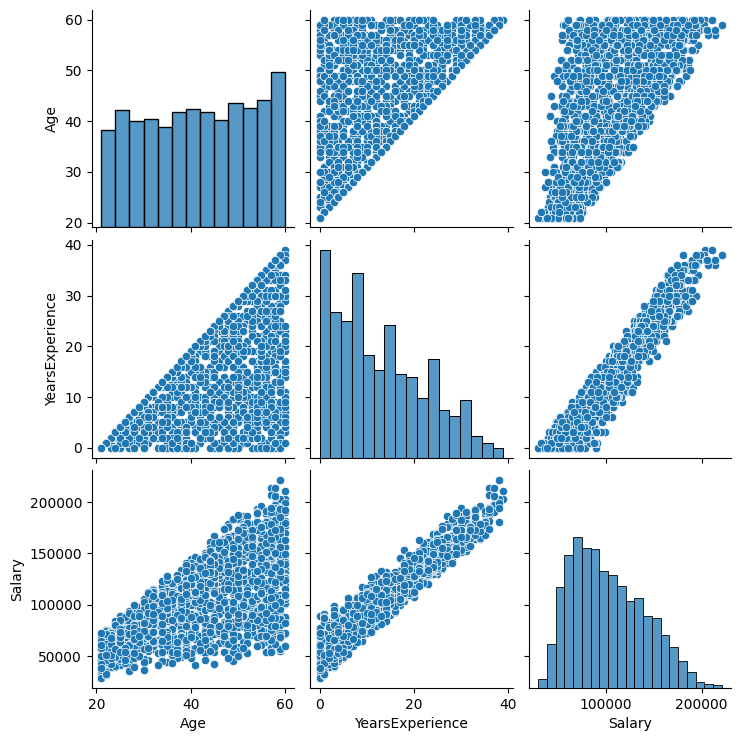

In [32]:
sns.pairplot(data=dataset)
plt.show()

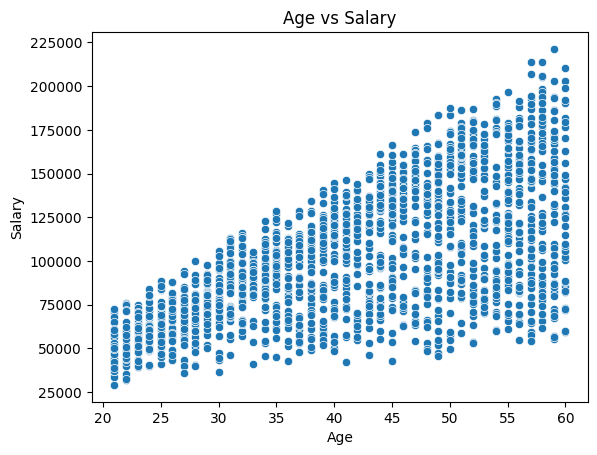

In [33]:
# 1. Check linearity of Age vs Salary
sns.scatterplot(data=dataset, x="Age", y="Salary")
plt.title("Age vs Salary")
plt.show()

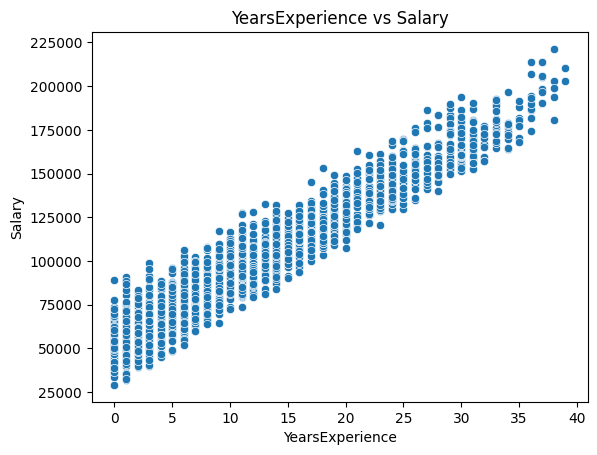

In [34]:
# 2. Check linearity of YearsExperience vs Salary
sns.scatterplot(data=dataset, x="YearsExperience", y="Salary")
plt.title("YearsExperience vs Salary")
plt.show()

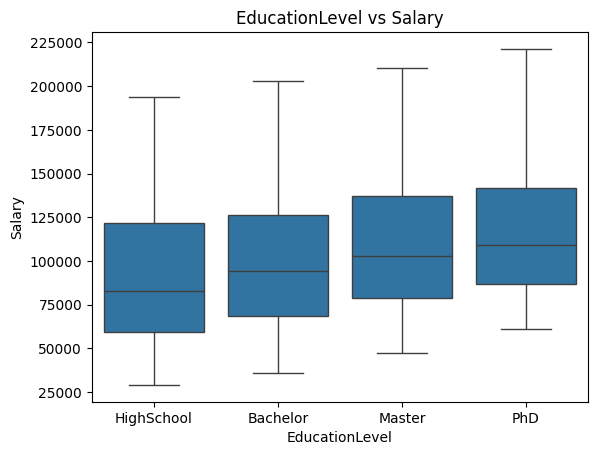

In [35]:
# 3. Check linearity of EducationLevel vs Salary, arrange the highschool, bachelors, masters, phd in order
sns.boxplot(data=dataset, x="EducationLevel", y="Salary", order=["HighSchool", "Bachelor", "Master", "PhD"])
plt.title("EducationLevel vs Salary")
plt.show()

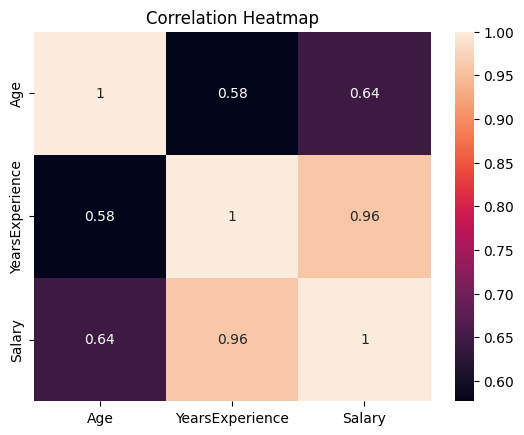

In [39]:
# Plot Correlation Heatmap
sns.heatmap(data=dataset[['Age', 'YearsExperience', 'Salary']].corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

#### Feature Engineering: One-Hot Encoding

In [40]:
# Feature Engineering: Convert EducationLevel to numerical values using one-hot encoding.
df_encoded = pd.get_dummies(dataset, columns=['EducationLevel'], drop_first=True, dtype=int)
df_encoded.head(5)

,Age,YearsExperience,Salary,EducationLevel_HighSchool,EducationLevel_Master,EducationLevel_PhD
0,28,1,56512,0,1,0
1,35,8,91587,0,1,0
2,55,5,70520,0,0,0
3,22,1,47779,0,0,0
4,59,1,69731,0,0,0


In [41]:
# Pop the column [Salary] out of the DataFrame and re-assign it to the end so it gets pushed to the right
df_encoded['Salary'] = df_encoded.pop('Salary')
df_encoded.head(5)

,Age,YearsExperience,EducationLevel_HighSchool,EducationLevel_Master,EducationLevel_PhD,Salary
0,28,1,0,1,0,56512
1,35,8,0,1,0,91587
2,55,5,0,0,0,70520
3,22,1,0,0,0,47779
4,59,1,0,0,0,69731


In [42]:
df_encoded.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Age                        2000 non-null   int64
 1   YearsExperience            2000 non-null   int64
 2   EducationLevel_HighSchool  2000 non-null   int64
 3   EducationLevel_Master      2000 non-null   int64
 4   EducationLevel_PhD         2000 non-null   int64
 5   Salary                     2000 non-null   int64
dtypes: int64(6)
memory usage: 93.9 KB


#### Create input and output variable for Multiple Linear Regression

In [44]:
x = df_encoded.iloc[:, :-1]  # input features (all columns except the last one)
y = df_encoded['Salary']

#### Split dataset into training and testing datasets

In [46]:
df_encoded.shape

(2000, 6)

In [45]:
from sklearn.model_selection import train_test_split

In [47]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [52]:
# verify the size of training datasets whether it is 80% of the original dataset
x_train.shape, y_train.shape

((1600, 5), (1600,))

In [53]:
# verify the size of testing datasets whether it is 20% of the original dataset
x_test.shape, y_test.shape

((400, 5), (400,))

#### Initialize and Train Multiple Linear Regression

In [54]:
from sklearn.linear_model import LinearRegression

In [55]:
lr = LinearRegression()

In [56]:
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 474.12, 3518.72,-8156.08, 9993.02,21640.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['Age','YearsExperience','EducationLevel_HighSchool', 'EducationLevel_Master','EducationLevel_PhD']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3.412e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [62]:
# Accuracy of the model on testing data
lr.score(x_test, y_test)  # R-squared value for testing data

0.9870116979422411

In [59]:
# The equation of this multiple linear regression model is:
# y = m1*x1 + m2*x2 + m3*x3 + m4*x4 + m5*x5 + b

lr.coef_  # coefficients (m1, m2, m3)


array([  474.12267435,  3518.72073555, -8156.07724075,  9993.01616937,
       21640.10171039])

In [60]:
lr.intercept_  # intercept (b)

np.float64(34123.00952282459)

In [ ]:
"""
The above coefficients and intercept values can be used to construct the final regression equation.
y = 474.12267435 * Age +  3518.72073555 * YearsExperience -  8156.07724075 * EducationLevel_HighSchool +  9993.01616937 * EducationLevel_Master +  21640.10171039 * EducationLevel_PhD +  34123.00952282459
"""

#### Accuracy Metrics

In [63]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [67]:
# Predict values
y_pred = lr.predict(x_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Metrics")
print("------------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Model Evaluation Metrics
------------------------
MAE: 4011.3630801277586
MSE: 20810479.660525538
RMSE: 4561.850464507307
R2 Score: 0.9870116979422411


C:\Users\riazu\AppData\Local\Temp\ipykernel_12528\1514863133.py:4: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', color='red', label='Perfect Prediction Line')


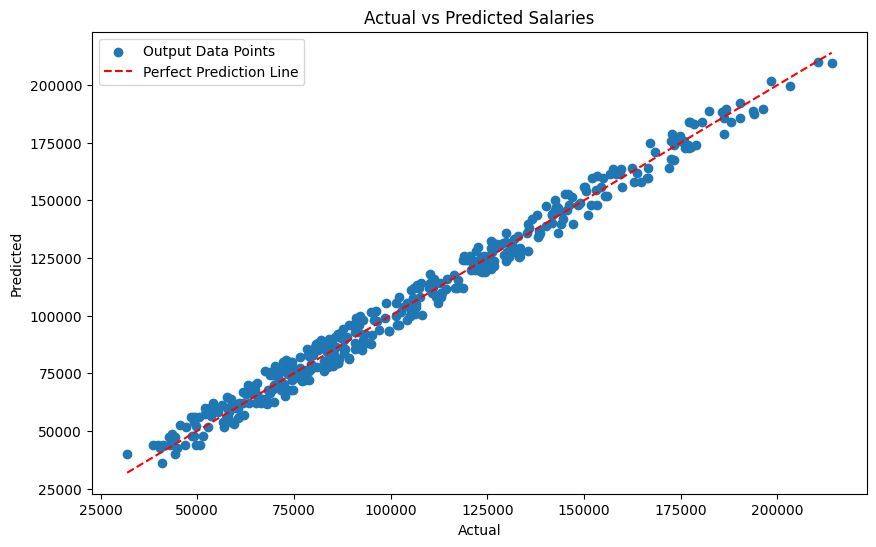

In [75]:
# Visualize the predicted vs actual values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, label='Output Data Points')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', color='red', label='Perfect Prediction Line')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted Salaries')
plt.legend()
plt.show()